# Лабораторная работа №2. Корреляционный анализ
Графики к части 2: данные `brainsize.txt`, корреляции признаков с `MRI_Count` отдельно для мужчин и женщин.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

df = pd.read_csv('brainsize.txt', sep='\t', na_values='NA')
features = ['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height', 'MRI_Count']
df.head()

,Gender,FSIQ,VIQ,PIQ,Weight,Height,MRI_Count
0,Female,133,132,124,118.0,64.5,816932
1,Male,140,150,124,NaN,72.5,1001121
2,Male,139,123,150,143.0,73.3,1038437
3,Male,133,129,128,172.0,68.8,965353
4,Female,137,132,134,147.0,65.0,951545


### Heatmap корреляций Пирсона (отдельно для женщин и мужчин)

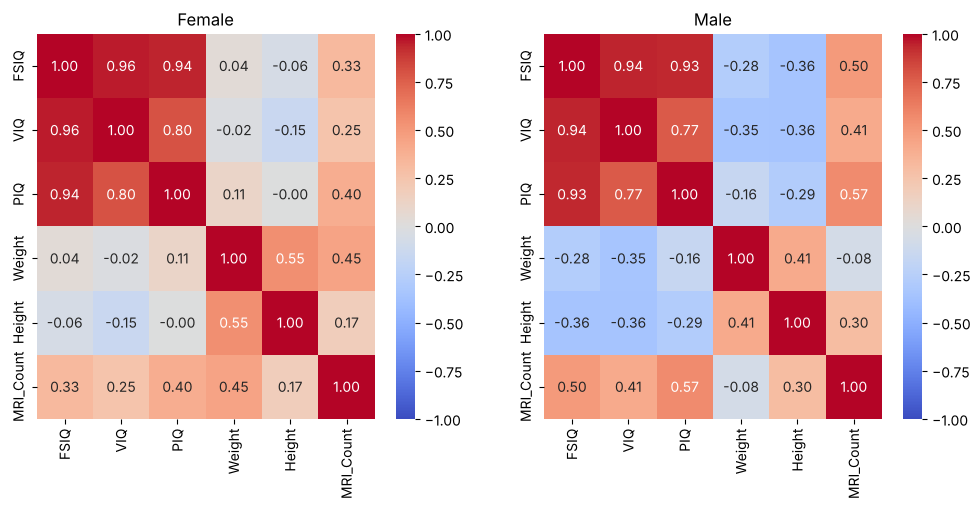

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (gender, group) in zip(axes, df.groupby('Gender')):
    sns.heatmap(group[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
    ax.set_title(gender)
plt.show()

### Scatter-графики всех пар признаков

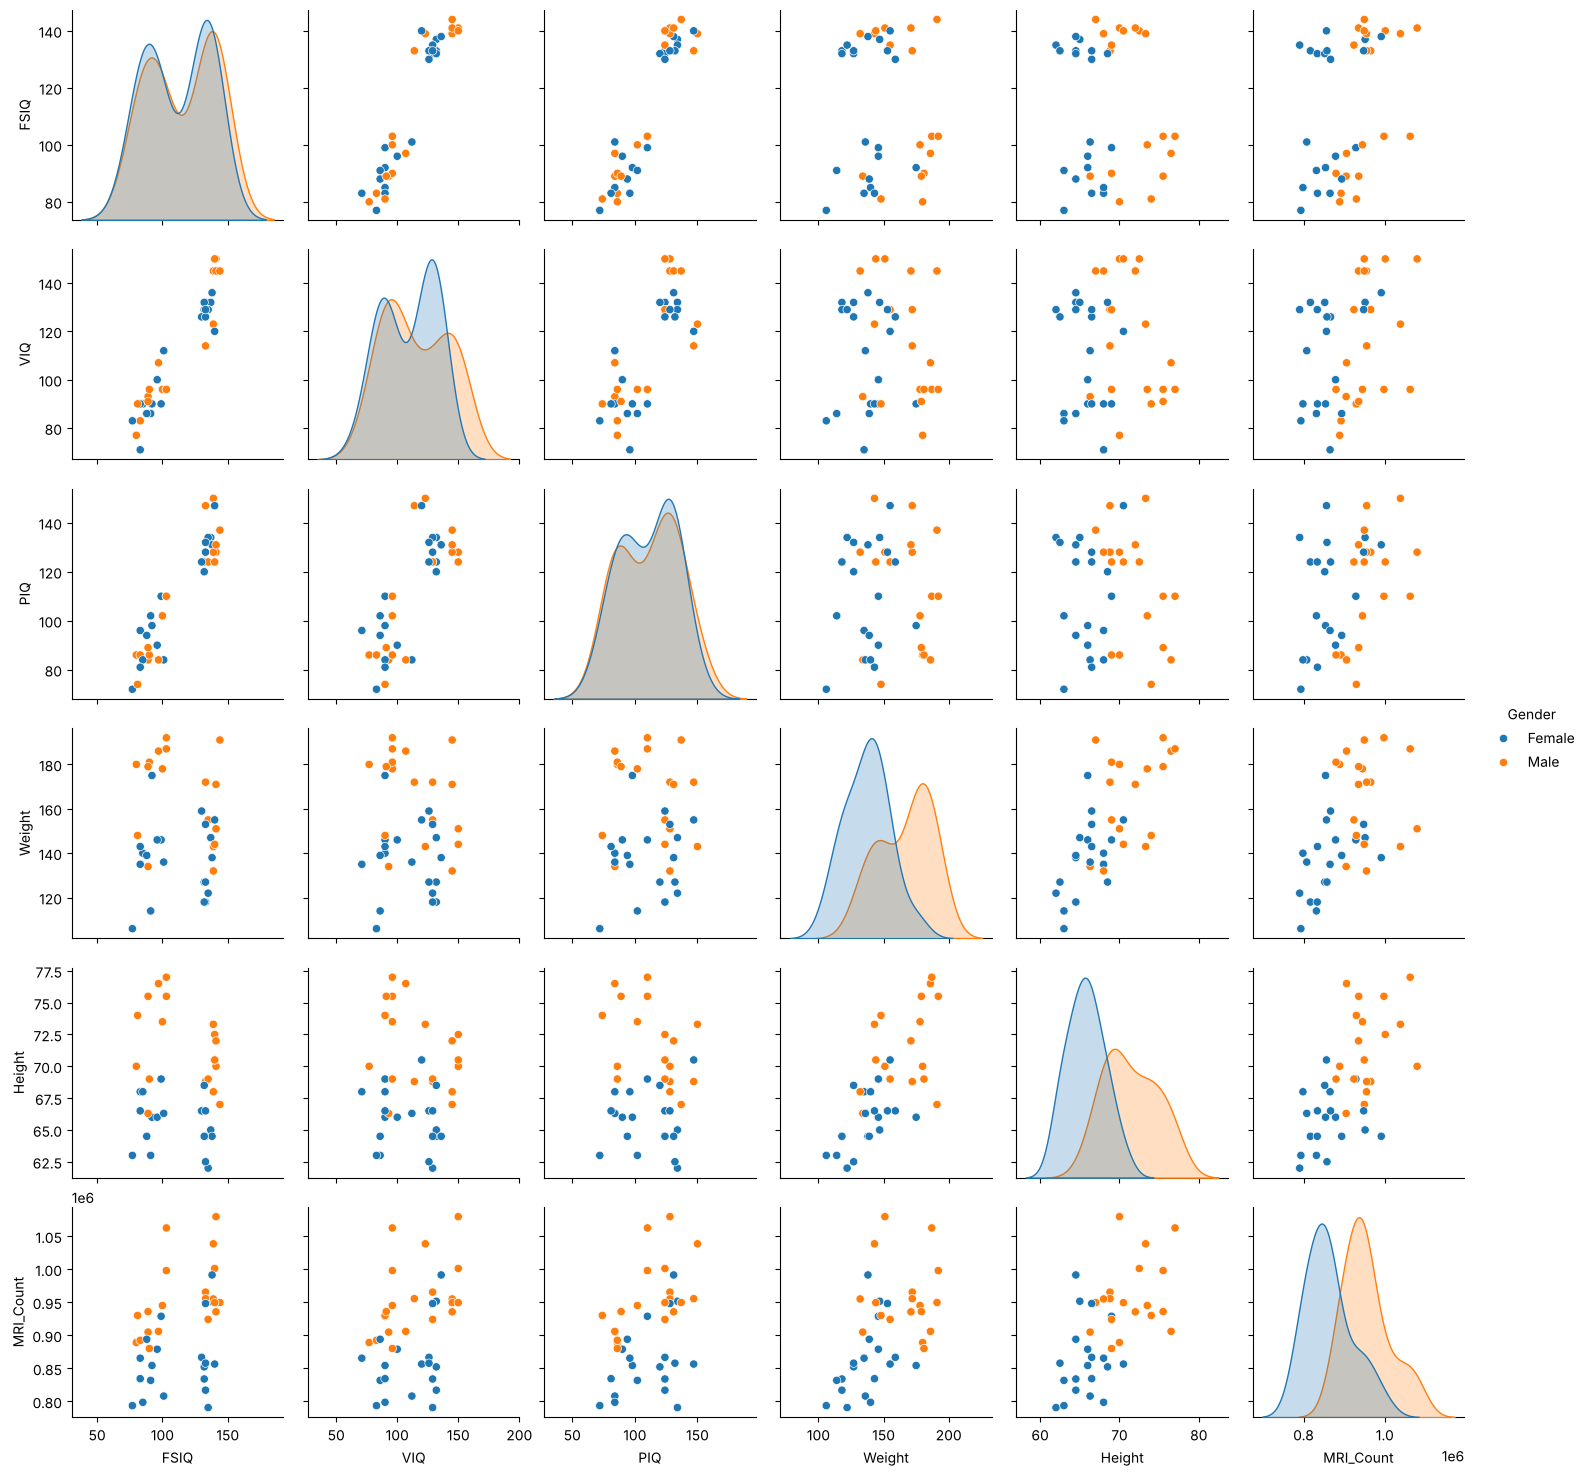

In [3]:
sns.pairplot(df, vars=features, hue='Gender')
plt.show()

### Зависимость MRI_Count от PIQ

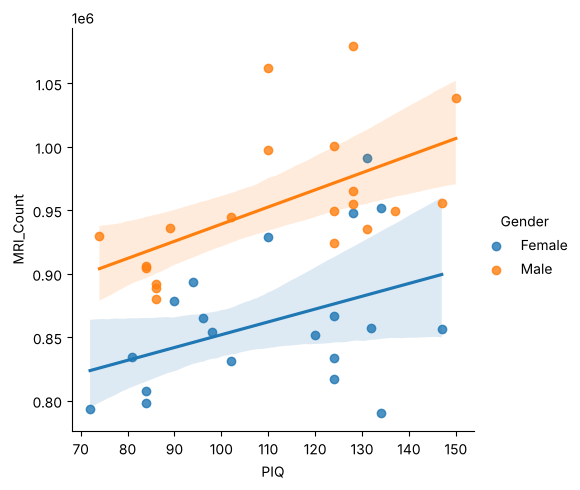

In [4]:
sns.lmplot(data=df, x='PIQ', y='MRI_Count', hue='Gender')
plt.show()

### Выводы
- В выборке 20 мужчин и 20 женщин; пропуски `NA` есть только в `Weight` и `Height`, при расчёте корреляции они игнорируются попарно.
- У мужчин `MRI_Count` сильнее всего связан с `PIQ` (r ≈ 0.57), затем с `FSIQ` (≈ 0.50) и `VIQ` (≈ 0.41); корреляция с `Weight` практически отсутствует (≈ -0.08).
- У женщин наибольшая корреляция с `Weight` (≈ 0.45), затем `PIQ` (≈ 0.40) и `FSIQ` (≈ 0.33).
- Признак с наибольшим модулем корреляции среди обеих групп — `PIQ` (мужчины, 0.568).
- Выборка маленькая (по 20 наблюдений в группе), поэтому корреляции такой величины нужно интерпретировать осторожно.